# AS HABILIDADES MAIS DIFÍCEIS NA VISÃO DOS ALUNOS E DA PROVA

## Hipótese

Nesse trecho do projeto avaliamos a dificuldade das questões. Quais áreas e habilidades apresentam um desafio maior aos alunos? Esse desafio é intencional do INEP ou se deve a outros fatores? O objetivo é analisar quais habilidades se mostram mais complexas aos alunos e como essa dificuldade se relaciona ao TRI.

## Metodologia e engenharia

Essa análise é divida em dois eixos, que se encontrarão ao final. 

Inicialmente, analisamos estruturalmente a dificuldade da prova. Cada questão conta com três parâmetros componentes da Teoria de Resposta ao Item (TRI). O segundo desses parâmetros mede exatamente a dificuldade prevista. A análise desse parâmetro nos permite entender diretamente quais questões são feitas intencionalmente para serem difíceis. Cruzando esse dado com a habilidade relacionada a cada questão, podemos finalmente estabelecer uma dificuldade intencional média para cada habilidade.

Em seguida, buscamos entender quais habilidade são mais difíceis para os alunos. Essa dificuldade percebida é medida através da taxa de erro das questões. Quanto maior a taxa de erro, mais difícil podemos considerar a questão. Novamente, relacionamos a questão à sua habilidade e temos ai uma dificuldade percebida média.

Finalmente, cruzamos essas médias obtidas para entender se as questões feitas para serem difíceis são de fato as mais difíceis. Essa conclusão permite entender melhor como o TRI funciona e também identificar em que áreas os alunos sentem maior dificuldade, o que ajuda a direcionar melhor a preparação acadêmica.

Para atingir o objetivo proposto criamos a tabela mart_TRI. Uma das principais características dessa tabela é que foi feita agrupando as questões por código do item, permitindo assim que um item seja contabilizado apenas uma vez mesmo que apareça em mais de uma prova. Cada habilidade têm vários itens ao longo do período analisado, portanto fazemos uma média de dificuldade TRI e taxa de acerto para cada habilidade dentro de cada área. Um primeiro gráfico de dispersão dará uma noção da comparação entre as áreas, avaliando ainda se há alguma relação entre dificuldade e taxa de acerto. Por fim, um ranking ajudará a visualizar as habilidades com maior dificuldade e menor taxa de acerto em cada área do conhecimento.

## Importação dos dados

In [1]:
import duckdb
import pandas as pd

# abrir a conexão com banco de dados
con = duckdb.connect('../database/enem.duckdb')

# criar a consulta em SQL
query = """
    SELECT * FROM mart_TRI
"""
# consultar a tabela e salvar em um dataframe
df = con.execute(query).df()

#Não esquecer de fechar a conexão
con.close()

# visualizar parte do dataframe
df

,Area,Habilidade,Descricao,Dificuldade média TRI,Taxa média de erro
0,CH,1,interpretar historicamente e/ou geograficament...,1.2060,61.11
1,CH,2,analisar a produção da memória pelas sociedade...,0.9630,56.55
2,CH,3,associar as manifestações culturais do present...,0.9530,54.15
3,CH,4,comparar pontos de vista expressos em diferent...,1.5243,55.88
4,CH,5,identificar as manifestações ou representações...,0.8451,53.20
...,...,...,...,...,...
115,MT,26,analisar informações expressas em gráficos ou ...,1.0865,57.22
116,MT,27,calcular medidas de tendência central ou de di...,1.4120,61.98
117,MT,28,resolver situação-problema que envolva conheci...,2.2587,75.77
118,MT,29,utilizar conhecimentos de estatística e probab...,1.4913,63.32


## Estratégia de visualização

Inicialmente, faremos uma visualização geral de dificuldade x taxa de erro em todas as habilidades. Essa primeira visualização será diferenciada com cores para identificar melhor cada área. Nossa intenção aqui é um panorama geral que nos permita identificar se há áreas mais/menos difíceis ou que registrem maior/menor quantidade de erros. Além disso, esse primeiro gráfico nos permite identificar alguma habilidade que eventualmente fuja do padrão.

Em seguida segmentamos a visualização para cada área do conhecimento. Assim será possível construir um "top 5" de habilidades mais difíceis para cada área. O ponto aqui é entender onde estão as maiores dificuldades dos alunos. Além disso, podemos também visualizar se as questões com maior taxa de erro são também as mais difíceis segundo o TRI.

## Visualização

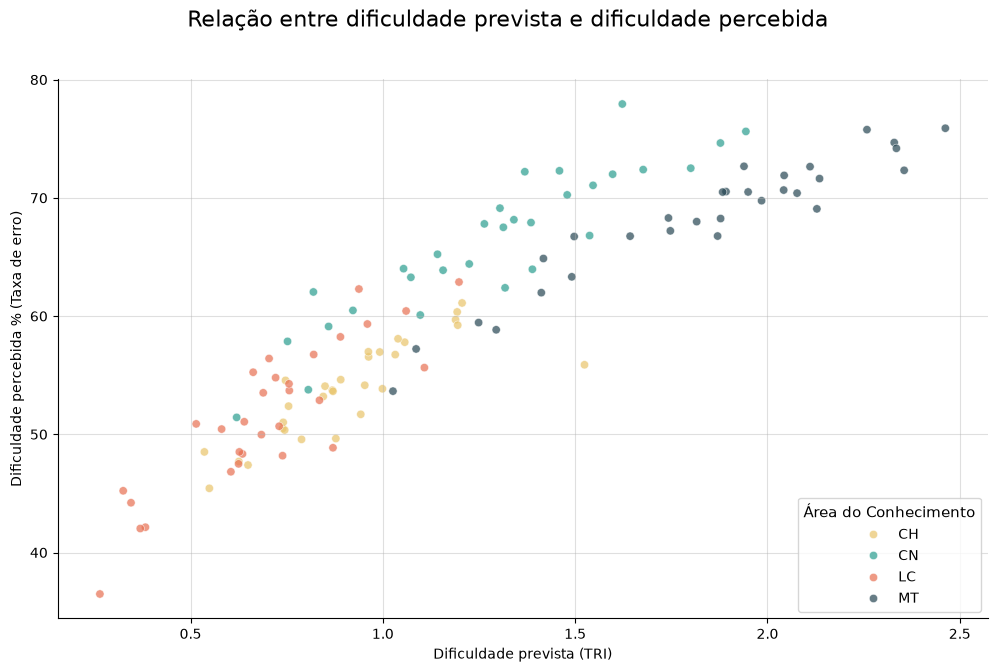

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Dicionário mapeando as siglas das áreas
cores_areas = {
    'LC': '#E76F51',
    'CH': '#E9C46A',
    'CN': '#2A9D8F',
    'MT': '#264653'
}

# criar o frame
fig, ax = plt.subplots(figsize=(12, 7))

# plotando o gráfico
ax = sns.scatterplot(
    data=df,
    x='Dificuldade média TRI',
    y='Taxa média de erro',
    hue = 'Area', # para pintar as bolhas por área
    palette = cores_areas, # aplicar as cores definidas acima
    alpha = 0.7, # transparência das bolhas
    ax=ax # especificar qual eixo deve ir esse gráfico (nesse caso só tem 1)
)

# títulos
fig.suptitle('Relação entre dificuldade prevista e dificuldade percebida', fontsize=16)
plt.xlabel('Dificuldade prevista (TRI)')
plt.ylabel('Dificuldade percebida % (Taxa de erro)')

# legenda
ax.legend(
    title='Área do Conhecimento', 
    title_fontsize='11', 
    fontsize='10', 
    loc='lower right', # Posiciona a legenda no canto inferior direito
    frameon=True       # Cria uma caixa ao redor da legenda
)

# controlar a transparência das barras do grid
ax.grid(alpha=0.4)

# remover as linhas superior e direita da caixa do gráfico.
sns.despine()

# Exportando o gráfico final em alta resolução
plt.savefig('../graficos/dificuldade_dispersao.png', dpi=300)

plt.show()

C:\Users\mvini\AppData\Local\Temp\ipykernel_3556\3864400664.py:74: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


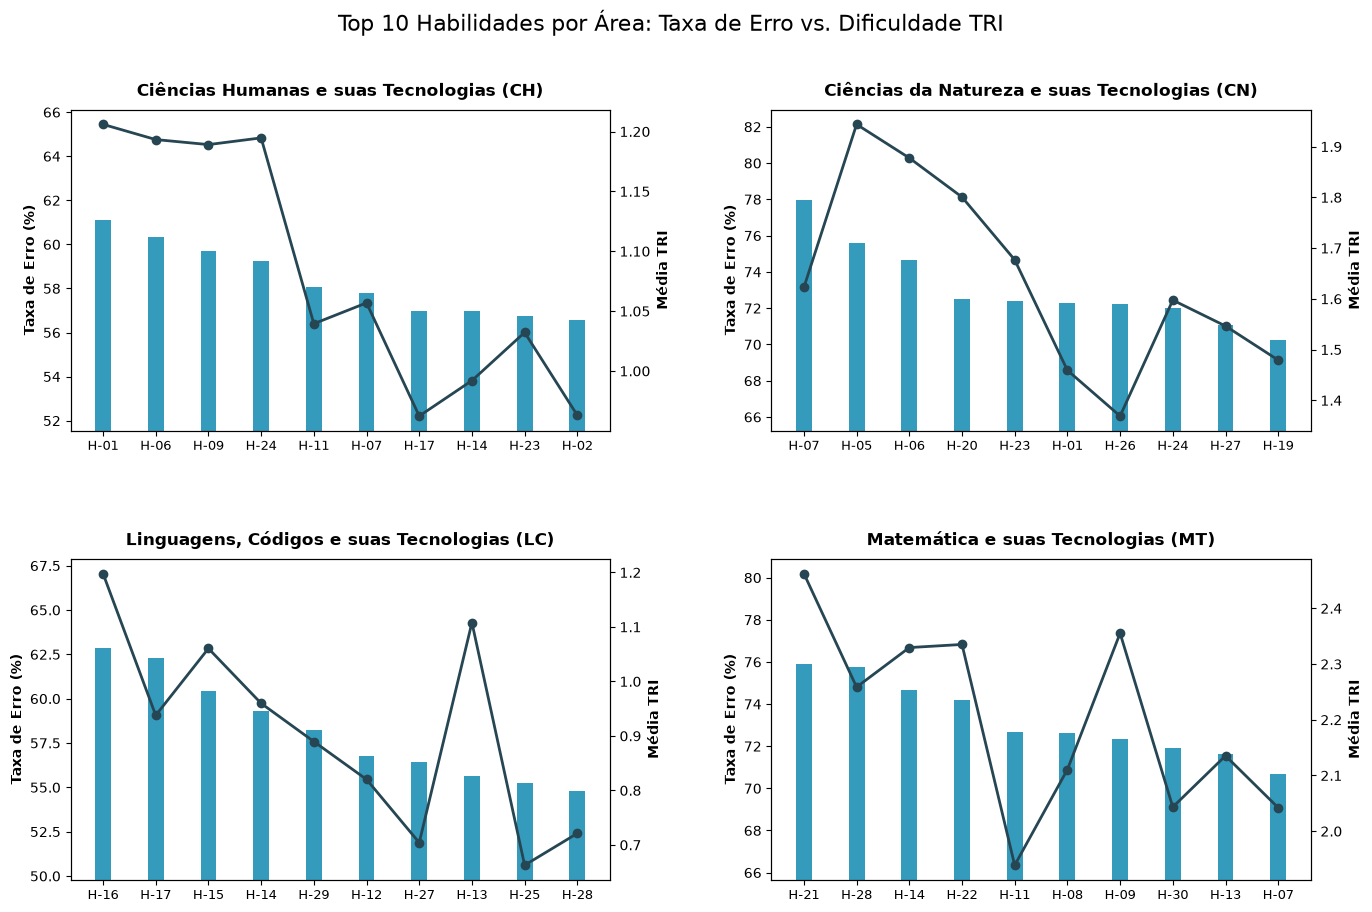

In [6]:
import numpy as np

# Definir as áreas do conhecimento
sg_areas = df['Area'].unique()

# Criar a moldura de uma figura 2x2
fig, axes = plt.subplots(2, 2, figsize=(16, 10), gridspec_kw={'wspace': 0.3, 'hspace': 0.4}) # gridspec afasta um pouco os gráficos um do outro
axes = axes.flatten()  # Transforma a matriz 2x2 em uma lista para facilitar o loop

#títulos das áreas
titulos_areas = [
    "Ciências Humanas e suas Tecnologias (CH)", 
    "Ciências da Natureza e suas Tecnologias (CN)", 
    "Linguagens, Códigos e suas Tecnologias (LC)", 
    "Matemática e suas Tecnologias (MT)"
]

# Cores
cor_barra = '#118AB2'
cor_linha = '#264653'

for i, area in enumerate(sg_areas):
    ax1 = axes[i] # define qual eixo está sendo trabalho nesse loop
    
    # Filtra e ordena o Top 10 da área da vez
    df_area = df[df['Area'] == area].copy()
    df_top10 = df_area.sort_values(by='Taxa média de erro', ascending=False).head(10) # ordem por taxa de erro
    df_top10['Habilidade'] = 'H-' + df_top10['Habilidade'].astype(str).str.zfill(2) # zfill serve para adicionar um zero a esquerda de números que só tem 1 algarismo

    # cria uma lista ordenada de posições para o matplotlib saber onde deve desenhar as barras e pontos da linha
    x_indexes = np.arange(len(df_top10))
    habilidades_str = df_top10['Habilidade'].astype(str).tolist() # para criar a lista de rotulos do eixo x
    
    # Eixo y esquerdo (taxa de erro)
    ax1.bar(
        x_indexes,
        df_top10['Taxa média de erro'], 
        width=0.3, 
        color=cor_barra, 
        alpha=0.85
    )

    ax1.set_ylabel('Taxa de Erro (%)', fontsize=10, fontweight='bold')
    ax1.tick_params(axis='y')
    ax1.set_xticks(x_indexes)
    ax1.set_xticklabels(habilidades_str, fontsize=9) # rotulos nas marcações do eixo
    ax1.set_ylim(0, 100)  # Padroniza a escala percentual em todos os subplots

    # Zoom dinâmico para destacar a diferença entre as barras
    ymin_barra = max(0, df_top10['Taxa média de erro'].min() - 5)
    ymax_barra = min(100, df_top10['Taxa média de erro'].max() + 5)
    ax1.set_ylim(ymin_barra, ymax_barra) # aplica tamanhos mínimo e máximo para cada barra
    
    # Eixo y direito (média TRI)
    ax2 = ax1.twinx()  # para colocar na mesma "posição" do gráfico acima
    
    ax2.plot(
        x_indexes,
        df_top10['Dificuldade média TRI'], 
        color=cor_linha, 
        marker='o', 
        linewidth=2, 
        markersize=6
    )
    ax2.set_ylabel('Média TRI', fontsize=10, fontweight='bold')
    ax2.tick_params(axis='y')
    ax2.grid(False)
    
    # Título do painel individual
    ax1.set_title(titulos_areas[i], fontsize=12, fontweight='bold', pad=10)

# Ajustes finais de layout global
plt.suptitle('Top 10 Habilidades por Área: Taxa de Erro vs. Dificuldade TRI', fontsize=16)
plt.tight_layout()

# Exportando o gráfico final em alta resolução
plt.savefig('../graficos/dificuldade_top10.png', dpi=300)

plt.show()

## Conclusões

O gráfico de dispersão nos confirma de imediato a suspeita inicial. De fato, há uma relação direta entre a dificuldade média de cada habilidade e sua taxa de erro. Essa relação indica que a calibração do parâmetro de dificuldade do TRI é eficiente. Também notamos nesse mesmo gráfico que existe uma distribuição de dificuldade heterogênea entre as áreas do conhecimento, com LC trazendo questões mais fáceis e MT com questões mais difíceis.

Partindo para a análise individual por área, começamos por CH. Aqui notamos que a habilidade 01 (interpretar historicamente e/ou geograficamente fontes documentais acerca de aspectos da cultura) apresenta maior erro médio e maior dificuldade prevista. Porém, logo percebemos que essa proporcionalidade não se mantém tão linear quanto esperado, especialmente nas habilidades 17 (analisar fatores que explicam o impacto das novas tecnologias no processo de territorialização da produção) e 02 (analisar a produção da memória pelas sociedades humanas), que apresentam uma dificuldade TRI mais baixa que as demais mas ainda assim figuram no top10 de maiores taxas de erro e por isso demandam uma atenção maior do estudante.

Passando para a área de CN, as duas primeiras barras já se destacam. A habilidade 07 (selecionar testes de controle, parâmetros ou critérios para a comparação de materiais e produtos, tendo em vista a defesa do consumidor, a saúde do trabalhador ou a qualidade de vida) apresenta uma desproporcionalidade entre dificuldade e taxa de erro, especialmente quando comparada às barras vizinhas. Esse fato indica que questões dessa habilidade não são feitas para serem difíceis, mas ainda assim os alunos sentem dificuldade. Seguindo no gráfico encontramos uma queda de dificuldade que não se traduz em queda de erros nas habilidades 01 (reconhecer características ou propriedades de fenômenos ondulatórios ou oscilatórios, relacionando-os a seus usos em diferentes contextos) e 26 (avaliar implicações sociais, ambientais e/ou econômicas na produção ou no consumo de recursos energéticos ou minerais, identificando transformações químicas ou de energia envolvidas nesses processos). Novamente essa variação pode indicar falta de domínio dos estudantes nas habilidades citadas.

O gráfico de LC nos apresenta um destaque imediato, a habilidade 13 (analisar as diversas produções artísticas como meio de explicar diferentes culturas, padrões de beleza e preconceitos). Apesar do notório salto de dificuldade TRI, a taxa de erro se mantém praticamente constante em relação às habilidades vizinhas. Trazendo o efeito oposto dos destaques anteriores, essa habilidade tende a ser mais amigável aos estudantes, pois o aumento de dificuldade não se traduz em aumento de erro.

Por fim, chegamos ao gráfico de MT. Aqui começamos pela habilidade 21 (resolver situação-problema cuja modelagem envolva conhecimentos algébricos) que traz a maior média de dificuldade TRI entre todas as áreas. Por isso já esperávamos que fosse também a habilidade com maior taxa de erro na área. Outro destaque está nas habilidades 11 (utilizar a noção de escalas na leitura de representação de situação do cotidiano) e 09 (utilizar conhecimentos geométricos de espaço e forma na seleção de argumentos propostos como solução de problemas do cotidiano), mas por razões inversas. Enquanto a habilidade 11 apresenta queda da dificuldade, a habilidade 09 retoma um crescimento de dificuldade acentuado. O que mais se destaca, porém, é que a taxa de erro das duas é praticamente igual, revelando domínio dos alunos na habilidade 09 e necessidade de melhora na habilidade 11.